[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch07-decoding-mini_workbook.ipynb)

# Greedy decoding, temperature, top-k, top-p after `It is a truth`

After Austen's first words, `It is a truth`, six next words have the
probabilities of the decoding lecture, chosen by hand: `that` is the most
probable, `universally` is Austen's own word. Which path of two words is the
most probable, toward which entropy the distribution tends as the temperature grows, and which set of
words is kept by top-k and by top-p?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

WORDS = ["that", "universally", "which", "full stop", "well", "not"]
P1 = np.array([0.40, 0.25, 0.15, 0.10, 0.06, 0.04])  # after "It is a truth", chosen by hand
FLAT_WORDS = ["the", "a", "she", "we", "all", "he"]
FLAT = np.array([0.20, 0.19, 0.18, 0.16, 0.14, 0.13])  # after "It is a truth that"
PEAKED_WORDS = ["acknowledged", "known", "accepted", "admitted", "held", "true"]
PEAKED = np.array([0.90, 0.05, 0.02, 0.01, 0.01, 0.01])  # after "It is a truth universally"
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 9})


def temperature(p, T):  # softmax(z / T), the same as p ** (1 / T) renormalised
    q = np.asarray(p, dtype=float) ** (1 / T)
    return q / q.sum()


def order(p):  # the words from the most probable down; ties in the order of the step
    return np.argsort(-np.asarray(p), kind="stable")


def top_k(p, k):  # the first k words of the order, renormalised
    q = np.zeros_like(p)
    q[order(p)[:k]] = p[order(p)[:k]]
    return q / q.sum()


def top_p(p, rho):  # the shortest prefix of the order with mass at least rho, renormalised
    o = order(p)
    n = np.searchsorted(np.cumsum(p[o]), rho) + 1
    q = np.zeros_like(p)
    q[o[:n]] = p[o[:n]]
    return q / q.sum()


def entropy(p):  # in nats
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def show(p, q, words, title, kept=True):  # the step's probabilities in grey, the result of the rule in red
    n = int((q > 0).sum())
    if kept:  # the words kept by a truncation, in the title of its own chart
        title += f": {n} {'word' if n == 1 else 'words'} kept"
    y = np.arange(len(words))[::-1]
    fig, ax = plt.subplots(figsize=(5.0, 2.8), layout="constrained")
    ax.barh(y + 0.2, p, 0.4, color="#9e9e9e", label="probability")
    ax.barh(y - 0.2, q, 0.4, color="#a6192e", label="after the rule")
    ax.set(yticks=y, yticklabels=words, xlim=(0, 1.05), xlabel="probability", title=title)
    ax.legend(fontsize=8, loc="lower right")
    plt.show()

## 1. Greedy decoding against Austen's two words

In greedy decoding the most probable word of each step is taken: `that`, then
the most probable word after `that`. Austen's own continuation is
`universally acknowledged`. Run the cell: what is the probability of the
greedy path of two words? Then set `FIRST` to `"universally"` and run it
again: which path is the more probable?

In [2]:
FIRST = "that"
assert FIRST in ("that", "universally"), "the tree has the steps after that, universally"
step, names = (FLAT, FLAT_WORDS) if FIRST == "that" else (PEAKED, PEAKED_WORDS)
p_first, j = P1[WORDS.index(FIRST)], int(np.argmax(step))
print(f"{FIRST} {names[j]}: {p_first:.2f} x {step[j]:.2f} = {p_first * step[j]:.3f}")

that the: 0.40 x 0.20 = 0.080


### Solution

In [3]:
g, a = P1[0] * FLAT[0], P1[1] * PEAKED[0]
display(Markdown(f"With greedy decoding, `that the` is written, with probability {P1[0]:.2f} x {FLAT[0]:.2f} = {g:.3f}. "
                 f"Austen's `universally acknowledged` has {P1[1]:.2f} x {PEAKED[0]:.2f} = {a:.3f}. "
                 f"At the first step its {P1[1]:.2f} is below the {P1[0]:.2f} of `that`, so with greedy decoding "
                 "`that` is taken; with beam search of width 2 both first words are kept and Austen's path is found."))

With greedy decoding, `that the` is written, with probability 0.40 x 0.20 = 0.080. Austen's `universally acknowledged` has 0.25 x 0.90 = 0.225. At the first step its 0.25 is below the 0.40 of `that`, so with greedy decoding `that` is taken; with beam search of width 2 both first words are kept and Austen's path is found.

## 2. Temperature

At temperature `T` the scores are divided by `T` before the softmax, the same
as raising each probability to the power `1 / T` and renormalising. Run the
cell at `T` 0.5: which word has the largest probability, and what is the
entropy in nats? Then set `T` to 5: how close is the entropy to `ln 6`, the
entropy of six equal probabilities?

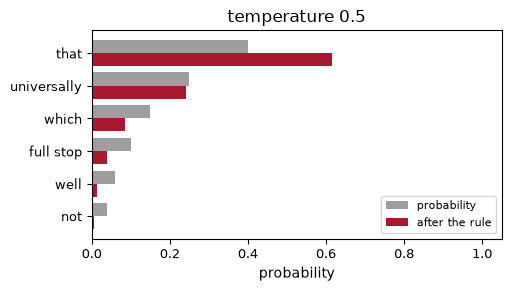

entropy 1.069 nats; at T = 1 1.525; ln 6 = 1.792


In [4]:
T = 0.5  # the probabilities reshaped by arithmetic; no word is drawn
q = temperature(P1, T)
show(P1, q, WORDS, f"temperature {T}", kept=False)
print(f"entropy {entropy(q):.3f} nats; at T = 1 {entropy(P1):.3f}; ln 6 = {np.log(6):.3f}")

### Solution

In [5]:
h = {t: entropy(temperature(P1, t)) for t in (0.5, 1, 5)}
display(Markdown(f"At every temperature `that` has the largest probability: the order of the six words is the "
                 f"same at every T. The entropy is {h[0.5]:.3f} nats at T = 0.5, {h[1]:.3f} at T = 1, "
                 f"{h[5]:.3f} at T = 5, against ln 6 = {np.log(6):.3f}: it grows with T toward ln 6."))

At every temperature `that` has the largest probability: the order of the six words is the same at every T. The entropy is 1.069 nats at T = 0.5, 1.525 at T = 1, 1.779 at T = 5, against ln 6 = 1.792: it grows with T toward ln 6.

## 3. Top-k against top-p on a flat and a peaked step

With top-k the first `K` words of the order are kept, with top-p the shortest
prefix of the order with mass at least `RHO`; both are renormalised. Run the
cell on the step after `It is a truth`: how many words are kept by each rule?
Then set `STEP, NAMES` to `FLAT, FLAT_WORDS`, then to `PEAKED, PEAKED_WORDS`.

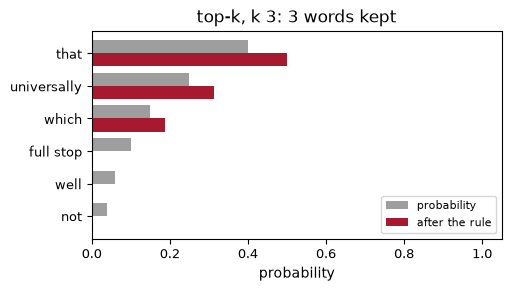

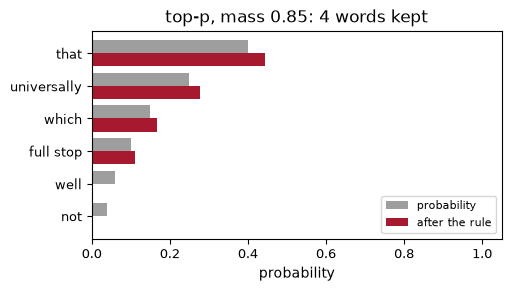

In [6]:
STEP, NAMES = P1, WORDS
K, RHO = 3, 0.85
show(STEP, top_k(STEP, K), NAMES, f"top-k, k {K}")
show(STEP, top_p(STEP, RHO), NAMES, f"top-p, mass {RHO}")

### Solution

In [7]:
rows = []
for name, s in (("flat step", FLAT), ("step after It is a truth", P1), ("peaked step", PEAKED)):
    n = int((top_p(s, 0.85) > 0).sum())
    rows.append(f"| {name} | 3 words | {n} {'word' if n == 1 else 'words'} |")
display(Markdown("| step | top-k, k 3 | top-p, mass 0.85 |\n|---|---|---|\n" + "\n".join(rows)
                 + "\n\nWith top-k the number of words is fixed; with top-p the mass kept is at least 0.85."))

| step | top-k, k 3 | top-p, mass 0.85 |
|---|---|---|
| flat step | 3 words | 5 words |
| step after It is a truth | 3 words | 4 words |
| peaked step | 3 words | 1 word |

With top-k the number of words is fixed; with top-p the mass kept is at least 0.85.

## Appendix. Order of temperature, truncation

In Hugging Face Transformers the scores are divided by the temperature before
the top-k and top-p cuts; in the default chain of llama.cpp, after them. The
step curve is the size of the top-p set at mass 0.85 on the step after
`It is a truth`, temperature first, for temperatures from 0.1 to 5. With
truncation first the size is the same at every temperature, and the size of
the top-k set is 3 at every temperature.

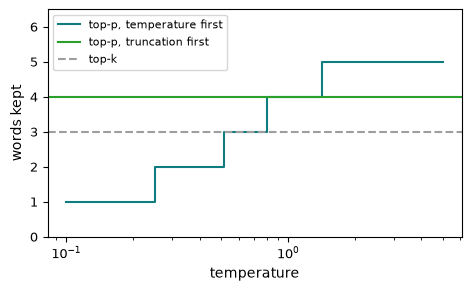

In [8]:
ts = np.exp(np.linspace(np.log(0.1), np.log(5), 400))
fig, ax = plt.subplots(figsize=(4.6, 2.8), layout="constrained")
ax.step(ts, [int((top_p(temperature(P1, t), 0.85) > 0).sum()) for t in ts], where="post", color="#0f7c80", label="top-p, temperature first")
ax.axhline(int((top_p(P1, 0.85) > 0).sum()), color="#2ca02c", label="top-p, truncation first")
ax.axhline(3, color="#9e9e9e", ls="--", label="top-k")
ax.set(xscale="log", xlabel="temperature", ylabel="words kept", ylim=(0, 6.5))
ax.legend(fontsize=8)
plt.show()

Beam search of width `B` on the tree of two steps: at the first step the `B`
most probable words are kept, each is extended by every word of its next
step, and the `B` most probable paths of two words are kept. The tree has the
steps after `that` and `universally`, so `B` is 1 or 2.

In [9]:
NEXT = {"that": (FLAT, FLAT_WORDS), "universally": (PEAKED, PEAKED_WORDS)}
def beam(B):  # beam search of width B over two steps
    kept = [(P1[i], WORDS[i]) for i in order(P1)[:B]]
    ext = [(pr * q, f"{w} {v}") for pr, w in kept for q, v in zip(*NEXT[w])]
    return sorted(ext, reverse=True)[:B]
for B in (1, 2):
    print(f"B {B}:", ", ".join(f"{path} {pr:.3f}" for pr, path in beam(B)))

B 1: that the 0.080
B 2: universally acknowledged 0.225, that the 0.080


**Exercise.** The functions `temperature`, `order`, `top_k`, `top_p` of the
lecture's listing are in the setup cell. For `T` 0.5, 1, 2: which positions
are nonzero in `top_k(temperature(p, T), 3)`, and how many entries are nonzero
in `top_p(temperature(p, T), 0.85)`?

In [10]:
p = np.array([0.40, 0.25, 0.15, 0.10, 0.06, 0.04])  # P1, as on the slide
T = 1  # the probabilities reshaped by arithmetic; no word is drawn
print("top-k positions:", np.nonzero(top_k(temperature(p, T), 3))[0])
print("top-p words:", int((top_p(temperature(p, T), 0.85) > 0).sum()))

top-k positions: [0 1 2]
top-p words: 4


### Solution

In [11]:
pos = {t: np.nonzero(top_k(temperature(P1, t), 3))[0].tolist() for t in (0.5, 1, 2)}
size = {t: int((top_p(temperature(P1, t), 0.85) > 0).sum()) for t in (0.5, 1, 2)}
display(Markdown(f"The top-k positions are {pos[0.5]} at every temperature: the order of the words is the same "
                 f"at every T. The top-p set has {size[0.5]}, {size[1]}, {size[2]} words at T = 0.5, 1, 2: "
                 "the mass of the first words falls as T grows, so more words are needed to reach 0.85."))

The top-k positions are [0, 1, 2] at every temperature: the order of the words is the same at every T. The top-p set has 2, 4, 5 words at T = 0.5, 1, 2: the mass of the first words falls as T grows, so more words are needed to reach 0.85.